# Temporal Olympic Medal Prediction with Performance Momentum
**UE24CS352A Machine Learning: Mini-Project (Team 53)**  
Ryona Aditree Ghosh (PES1UG24AM233) · Rishit V N S (PES1UG24AM225)

This notebook is the live demo. It walks through the pipeline step by step using the `olympic_momentum` package in `src/`.
Running `python scripts/run_pipeline.py` gives exactly the same results in one command.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace

from olympic_momentum.config import ExperimentConfig, MODEL_SPECS, HISTORICAL_FEATURES, TARGET
from olympic_momentum.data import build_country_year_table
from olympic_momentum.features import build_temporal_features, PerformanceMomentum
from olympic_momentum.experiment import (prepare_dataset, tune_forest, evaluate_on_year, summarise,
                                         bootstrap_mae_difference, forecast, load_actuals, score_forecast)
pd.set_option('display.precision', 3)

## 1. Load and clean the data
We start from athlete-level rows (one row per athlete per event) and collapse them to **one row per Country × Summer Games**.
Team medals are counted once per event, the same way official medal tables count them.

In [2]:
table = build_country_year_table()
print(table.shape)
table[table.Year == 2016].nlargest(8, TARGET)

(2770, 10)


,Country,Year,Athletes,Sports,Events,Gold,Silver,Bronze,Total_Medals,Is_Host
2613,USA,2016,555,33,245,46,37,38,121,0
521,China,2016,429,32,211,26,18,26,70,0
2586,UK,2016,360,26,198,27,23,17,67,0
2070,Russia,2016,284,29,181,19,17,20,56,0
863,France,2016,392,32,202,10,18,14,42,0
913,Germany,2016,418,29,217,17,10,15,42,0
1286,Japan,2016,335,32,186,12,8,21,41,0
138,Australia,2016,420,31,194,8,11,10,29,0


## 2. Temporal features (no leakage)
Every feature for Games *t* comes only from that country's **earlier** appearances (`groupby().shift()`).

In [3]:
config = ExperimentConfig()
df = prepare_dataset(config.split)
df.loc[(df.Country == 'UK') & df.Year.between(2000, 2020), ['Year', TARGET] + HISTORICAL_FEATURES]

,Year,Total_Medals,Previous_Medals,Previous_Gold,Previous_Athletes,Previous_Sports,Previous_Events,Historical_Medal_Growth,Historical_Athlete_Growth,Rolling_3_Medal_Avg,Medal_Efficiency
2773,2000,28.0,15.0,1.0,300.0,22.0,175.0,-0.272,-0.212,19.667,0.050
2774,2004,30.0,28.0,11.0,310.0,23.0,179.0,0.595,0.033,21.000,0.090
2775,2008,48.0,30.0,9.0,264.0,24.0,162.0,0.067,-0.160,24.333,0.114
2776,2012,65.0,48.0,19.0,304.0,23.0,185.0,0.458,0.141,35.333,0.158
2777,2016,67.0,65.0,29.0,530.0,32.0,249.0,0.298,0.554,47.667,0.123
2778,2020,NaN,67.0,27.0,360.0,26.0,198.0,0.030,-0.386,60.000,0.186


## 3. Performance Momentum
**Momentum score:** the mean of the z-scored medal growth, athlete growth and medal efficiency. The scaler is fitted **only on training Games**.

**Momentum target (our proposal):** instead of predicting the medal count, the model predicts the country's momentum,
`log(1+medals_t) − log(1+medals_{t−1})`, and adds it back to the previous count. Trees cannot extrapolate, so this lets one leaf
serve a 3-medal nation and a 90-medal nation that are on the same trajectory.

In [4]:
train = df[df.Year.between(1964, 2012)]
mom = PerformanceMomentum().fit(train)
rio = df[df.Year == 2016].assign(Momentum=lambda d: mom.score(d))
rio.nlargest(8, 'Momentum')[['Country', 'Previous_Medals', TARGET, 'Momentum']]

,Country,Previous_Medals,Total_Medals,Momentum
1237,Iran,12.0,8.0,2.195
936,Gabon,1.0,0.0,1.410
1352,Jamaica,12.0,11.0,1.408
581,Colombia,8.0,8.0,1.304
2161,Qatar,2.0,1.0,1.297
355,Botswana,1.0,0.0,1.222
183,Azerbaijan,10.0,18.0,1.186
2714,Tunisia,3.0,3.0,1.152


## 4. Tune once on the 2012 validation Games
One shared Random Forest setting for every model, so differences come only from features and targets.

In [5]:
demo = replace(config, seeds=(0,), forest=replace(config.forest, n_estimators=150))
params, grid = tune_forest(df, demo)
print(params)
grid.pivot_table(index='model', columns=['min_samples_leaf', 'max_features'], values='validation_MAE').round(3)

ForestParams(n_estimators=150, min_samples_leaf=10, max_features=0.6, random_state=42, n_jobs=-1)


min_samples_leaf                1             3             5             10  \
max_features                   0.6    1.0    0.6    1.0    0.6    1.0    0.6   
model                                                                          
Baseline                     1.648  1.635  1.387  1.477  1.311  1.426  1.244   
Historical + Momentum Score  1.531  1.511  1.467  1.517  1.449  1.499  1.442   
Historical Features          1.493  1.513  1.429  1.514  1.455  1.474  1.423   
Momentum Target              1.271  1.323  1.259  1.328  1.254  1.287  1.228   
Momentum Target + Score      1.317  1.315  1.290  1.307  1.233  1.273  1.236   
Paper Two-Stage              1.410  1.481  1.461  1.530  1.410  1.487  1.403   

min_samples_leaf                    
max_features                   1.0  
model                               
Baseline                     1.388  
Historical + Momentum Score  1.514  
Historical Features          1.480  
Momentum Target              1.258  
Momentum Target + Score      1.275  
Paper Two-Stage              1.474

## 5. Held-out test: Rio 2016
Train on 1964–2012, predict 2016.

In [6]:
metrics, preds = evaluate_on_year(df, 2016, 1964, params, seeds=(0, 1, 2))
summary = summarise(metrics)
summary[['MAE_mean', 'RMSE_mean', 'R2_mean', 'Top10_MAE_mean']]

,MAE_mean,RMSE_mean,R2_mean,Top10_MAE_mean
model,,,,
Baseline,1.609,3.858,0.912,12.359
Historical Features,1.470,3.743,0.917,11.884
Historical + Momentum Score,1.511,3.854,0.912,12.455
Paper Two-Stage,1.473,3.872,0.912,12.057
Momentum Target,1.303,3.371,0.933,10.167
Momentum Target + Score,1.295,3.384,0.932,10.064


In [7]:
sig = bootstrap_mae_difference(preds[TARGET], preds['Momentum Target'], preds['Historical Features'], 2000)
print('MAE(Momentum Target) - MAE(Historical):', sig)

MAE(Momentum Target) - MAE(Historical): {'observed': -0.1681714320414474, 'ci_low': -0.3266231153155083, 'ci_high': -0.018260905875787305, 'prob_a_better': 0.985}


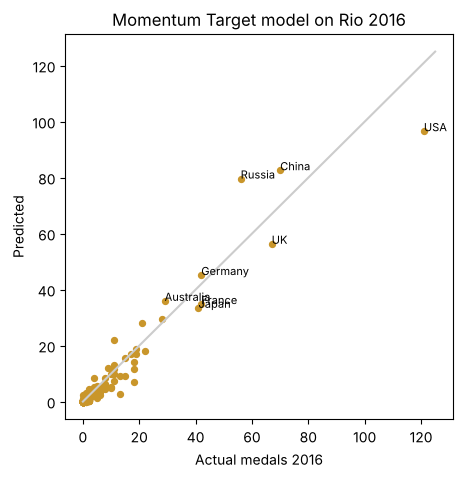

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(preds[TARGET], preds['Momentum Target'], s=18, c='#c9962b')
ax.plot([0, 125], [0, 125], c='#ccc')
for _, r in preds.nlargest(8, TARGET).iterrows():
    ax.annotate(r.Country, (r[TARGET], r['Momentum Target']), fontsize=8)
ax.set(xlabel='Actual medals 2016', ylabel='Predicted', title='Momentum Target model on Rio 2016');

In [9]:
preds.nlargest(10, TARGET)[['Country', TARGET, 'Previous_Medals', 'Historical Features', 'Momentum Target']].round(1)

,Country,Total_Medals,Previous_Medals,Historical Features,Momentum Target
192,USA,121.0,103.0,99.0,96.6
39,China,70.0,89.0,90.8,82.6
191,UK,67.0,65.0,80.1,56.4
150,Russia,56.0,82.0,82.1,79.7
62,France,42.0,35.0,39.5,34.8
66,Germany,42.0,44.0,46.7,45.2
89,Japan,41.0,38.0,33.7,33.5
10,Australia,29.0,35.0,43.9,36.0
86,Italy,28.0,28.0,32.8,29.4
33,Canada,22.0,18.0,19.3,18.0


## 6. Rolling-origin backtest
Results from the full run (`results/rolling_origin_mae.csv`): each Games is predicted from all earlier Games.

In [10]:
pd.read_csv('../results/rolling_origin_mae.csv', index_col=0).round(3)

,1996,2000,2004,2008,2012,2016,Average
model,,,,,,,
Baseline,2.014,1.724,1.478,1.702,1.250,1.606,1.629
Historical Features,1.920,1.694,1.442,1.667,1.395,1.474,1.599
Historical + Momentum Score,1.914,1.710,1.464,1.687,1.431,1.501,1.618
Paper Two-Stage,1.856,1.628,1.376,1.630,1.369,1.490,1.558
Momentum Target,1.825,1.300,1.111,1.473,1.238,1.298,1.374
Momentum Target + Score,1.847,1.316,1.130,1.498,1.244,1.296,1.389


## 7. A real forecast: Tokyo 2020
The dataset stops at 2016, so the 2020 forecast is made without any 2020 information and then scored against the real medal table.

In [11]:
future = forecast(df, params, config.split, seeds=(0,))
future, tokyo = score_forecast(future, load_actuals())
display(tokyo.round(3))
future.head(12)[['Country', 'Previous_Medals', 'Historical Features', 'Momentum Target', 'Actual']].round(1)

,MAE,RMSE,R2,Top10_MAE
model,,,,
Baseline,1.861,3.825,0.927,12.403
Historical Features,1.565,3.397,0.943,11.572
Historical + Momentum Score,1.569,3.360,0.944,11.433
Paper Two-Stage,1.567,3.420,0.942,11.675
Momentum Target,1.568,3.699,0.932,12.281
Momentum Target + Score,1.556,3.741,0.931,12.368


,Country,Previous_Medals,Historical Features,Momentum Target,Actual
0,USA,121.0,103.8,107.3,113
1,China,70.0,77.4,66.7,95
2,UK,67.0,76.6,66.2,64
3,Russia,56.0,71.1,54.3,71
4,Japan,41.0,38.1,45.0,58
5,Germany,42.0,52.5,42.5,37
6,France,42.0,43.8,40.6,33
7,Italy,28.0,32.9,30.8,40
8,Australia,29.0,38.2,29.1,46
9,Canada,22.0,24.1,22.2,24


## 8. Conclusions
* Learning **momentum** (change versus the previous Games) is the strongest design: it gives the lowest error on Rio 2016 and in every backtest Games.
* Adding the composite momentum **score** as one more feature does **not** help a Random Forest that already has its components. This is an honest negative result.
* On Tokyo 2020 (COVID-delayed, Japan hosting) all the history-based models finish level, which shows the limits of using only Olympic history.